<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Imbalanced Data - Solution

---

### About
Understand the challenges of imbalanced data and apply techniques to address class imbalance in data sets.  This notebook uses the [`imbalanced-learn`](https://imbalanced-learn.org/stable/) library and the examples within it extensively.

`imbalanced-learn` library: https://imbalanced-learn.org/stable/

### Learning Objectives
- Describe when imbalanced data is a problem
- Identify methods for handling imbalanced data and appropriately evaluating performance
- Apply the [`imbalanced-learn`](https://imbalanced-learn.org/stable/index.html) library to oversample minority classes
- Apply the [`imbalanced-learn`](https://imbalanced-learn.org/stable/index.html) library to create synthetic minority class observations

### Notebook Guide

- Imports, and install `imbalanced-learn` package, if needed
- Data SetUp
- Model Setup (Logistic Regression)
- Option 1: Oversample the minority class
- Option 2: Create synthetic data points similar to the minority class
    - SMOTE
    - ADASYN
- Option 3: Overweight minority class importance in algorithms
- Option 4: Change the class cutoff threshold

---
### Metrics

- ALWAYS think about your evaluation metrics AND how a null baseline model performs compared to your model. 
- Check out the confusion matrix.
- Consider using balanced accuracy if you care about all outcome classes equally.



# Imports, and install `imbalanced-learn` package if needed

In [2]:
# % pip install -U imbalanced-learn

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, ConfusionMatrixDisplay, 
                            recall_score, precision_score, f1_score)

from sklearn.datasets import fetch_openml
from imblearn.datasets import make_imbalance

We'll use an example data set used within the User Guide in the docs (see [here](https://imbalanced-learn.org/stable/common_pitfalls.html)): the adult census dataset. As with the User Guide, for the sake of simplicity we will only use the numerical features. Also, we will make the dataset more imbalanced.

In [4]:
# Option 1: fetch the data from only, select only the numerical features, and make the data imbalanced.  If you do it this way, skip to the 
# next section from here (Data Setup)

# X, y = fetch_openml(data_id=1119, as_frame=True, return_X_y=True, parser='auto')
# X = X.select_dtypes(include="number")
# X, y = make_imbalance(X, y, sampling_strategy={">50K": 300}, random_state=1) # a convenience method for making imbalanced data

In [5]:
# Option 2: read in the data (note: this data has already been made more imbalanced)

claims = pd.read_csv('../data/imbl_data.csv', index_col=0)

In [6]:
claims.head()

,age,fnlwgt:,education-num:,capital-gain:,capital-loss:,hours-per-week:,class
0,39,77516,13,2174,0,40,<=50K
1,50,83311,13,0,0,13,<=50K
2,38,215646,9,0,0,40,<=50K
3,53,234721,7,0,0,40,<=50K
4,28,338409,13,0,0,40,<=50K


In [7]:
claims.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25020 entries, 0 to 27605
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              25020 non-null  int64 
 1   fnlwgt:          25020 non-null  int64 
 2   education-num:   25020 non-null  int64 
 3   capital-gain:    25020 non-null  int64 
 4   capital-loss:    25020 non-null  int64 
 5   hours-per-week:  25020 non-null  int64 
 6   class            25020 non-null  object
dtypes: int64(6), object(1)
memory usage: 1.5+ MB


In [8]:
claims['class'].value_counts()

class
<=50K    24720
>50K       300
Name: count, dtype: int64

In [9]:
X = claims.drop(columns=['class'])
y = claims['class']

In [10]:
# select only the numerical features

X = X.select_dtypes(include="number")


# Data Setup 

In [11]:
# train test split 
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=6) 

In [12]:
# scale the data
ss = StandardScaler()

X_train_ss = ss.fit_transform(X_train)
X_test_ss = ss.transform(X_test)

# Model Setup (Logistic Regression)

In [13]:
logr = LogisticRegression(max_iter=1_000)
logr.fit(X_train_ss, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [14]:
logr.score(X_test_ss, y_test)

0.9883293365307754

The accuracy looks very high.

## What metrics do we know?

Helper code provided to review common metrics:

In [15]:
def evaluation(X_test, y_test, preds, model):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
    
    b_acc = balanced_accuracy_score(y_test, preds)
    recall = recall_score(y_test, preds, pos_label = ">50K")
    prec = precision_score(y_test, preds, pos_label = ">50K")
    f1 = f1_score(y_test, preds, pos_label = ">50K")

    print(f'balanced_accuracy: {b_acc}')
    print(f'recall: {recall}')
    print(f'precision: {prec}')
    print(f'f1 score: {f1}')

    return {
        'balanced_accuracy': b_acc,
        'recall': recall,
        'precision': prec,
        'f1_score': f1
    }

balanced_accuracy: 0.5330906148867314
recall: 0.06666666666666667
precision: 0.625
f1 score: 0.12048192771084337


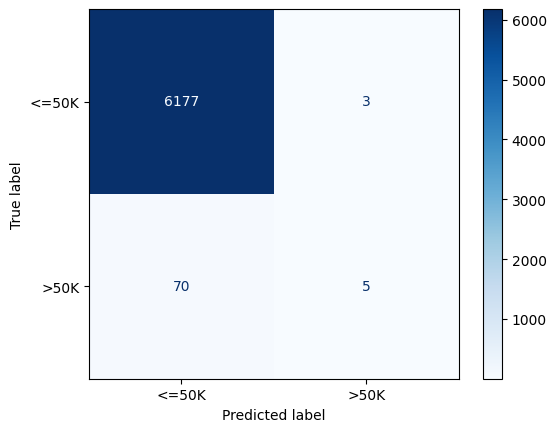

In [16]:
# setup and call the evaluation function defined above

scores = []
preds1 = logr.predict(X_test_ss)
scores.append(evaluation(X_test_ss, y_test, preds1, logr))

### Review Null Model, using the balanced accuracy score

In [17]:
y_test.value_counts()

class
<=50K    6180
>50K       75
Name: count, dtype: int64

In [18]:
null_preds = ['<=50K']*len(y_test)

In [19]:
balanced_accuracy_score(y_test, null_preds)

0.5

Notice that we had very high accuracy with the first model but it's misleading due to the imbalanced classes. We can see that with the [balanced accuracy score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html) (also see [here](https://scikit-learn.org/stable/modules/model_evaluation.html#balanced-accuracy-score)), which is an average of the recall (sensitivity) obtained on each class.

$$
\text{Balanced Accuracy} = \frac{1}{N} \sum_{i=1}^{N} \frac{TP_i}{TP_i + FN_i}
$$

Let's correct for this!

---
# Option 1: Oversample the minority class

Use random sampling with replacement. But use `imbalanced-learn`'s pipeline, not just `df.sample()`.

#### Use **`imbalanced-learn`'s** `make_pipeline` with a `GridSearchCV` object

This ensures the test-set data has similar class imbalance (so you don't overstate your results' generalizability to new data). ⭐️

In [20]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import make_pipeline

In [21]:
pipe = make_pipeline(RandomOverSampler(random_state=34), LogisticRegression(max_iter=1_000))
pipe

,steps,"[('randomoversampler', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,random_state,34
,sampling_strategy,'auto'
,shrinkage,None
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0


In [22]:
gs = GridSearchCV(pipe, {'randomoversampler__sampling_strategy': [.25, .5, .75, 1]}, n_jobs=-1)

In [23]:
gs.fit(X_train_ss, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'randomoversampler__sampling_strategy': [0.25, 0.5, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information

In [24]:
gs.score(X_test_ss, y_test)

0.9641886490807354

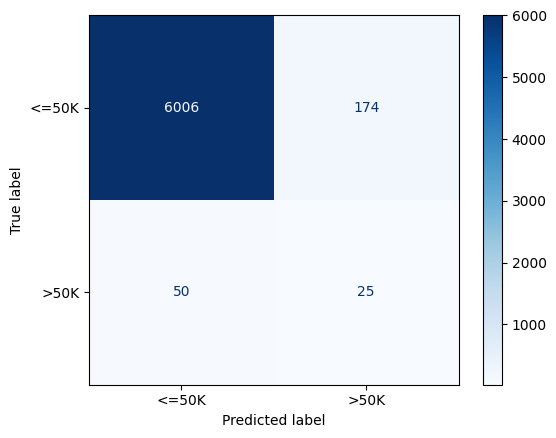

In [25]:
ConfusionMatrixDisplay.from_estimator(gs, X_test_ss, y_test, cmap='Blues');

In [26]:
pd.DataFrame(gs.cv_results_)['mean_test_score']

0    0.960245
1    0.906208
2    0.851106
3    0.798828
Name: mean_test_score, dtype: float64

### Smarter Move: Grid Search with balanced accuracy as your scoring metric

You can change the scoring metric for `GridSearchCV`. It will then pick the model that hasn't the best mean score on that metric.

### TRY IT!

In [27]:
gs2 = GridSearchCV(pipe,
                 param_grid=
                  {'randomoversampler__sampling_strategy' : [.25, .5, .75, 1.0]},
                 n_jobs=-1, scoring='balanced_accuracy')

In [28]:
gs2.fit(X_train_ss, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'randomoversampler__sampling_strategy': [0.25, 0.5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity

In [29]:
gs2.best_params_

{'randomoversampler__sampling_strategy': 0.75}

In [30]:
preds2 = gs2.predict(X_test_ss)

balanced_accuracy: 0.7216504854368933
recall: 0.5866666666666667
precision: 0.047311827956989246
f1 score: 0.08756218905472637


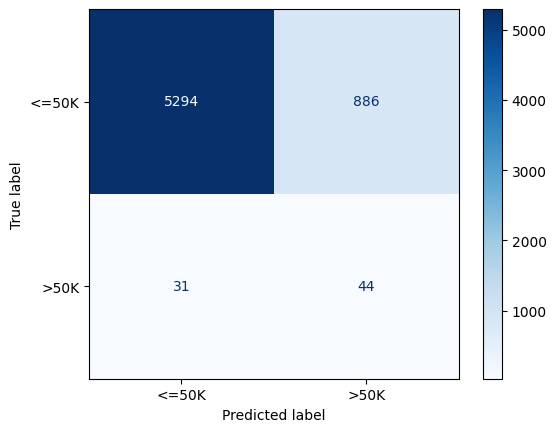

In [31]:
scores.append(evaluation(X_test_ss, y_test, preds2, gs2))

In [32]:
pd.DataFrame(scores, index=['logr', 'RandomOverSampler'])

,balanced_accuracy,recall,precision,f1_score
logr,0.533091,0.066667,0.625000,0.120482
RandomOverSampler,0.721650,0.586667,0.047312,0.087562


**Risk:** overfitting the training data. Look at the training and test set scores. Good idea to score on balanced accuracy when grid searching. 👍

---
# Option 2: Create synthetic data points similar to the minority class

**SMOTE** (Synthetic Minority Over-sampling Technique) - make some fake data of the minority class. 

Interpolates to create more minority class observations.

![scatterplots with SMOTE and ADASYN](../assets/smote-docs.png) From the docs: https://imbalanced-learn.org/stable/over_sampling.html#naive-random-over-sampling

In [33]:
from imblearn.over_sampling import SMOTE

In [34]:
pipe3 = make_pipeline(SMOTE(random_state=34), LogisticRegression(max_iter=1_000))

In [35]:
pipe3

,steps,"[('smote', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,random_state,34
,sampling_strategy,'auto'
,k_neighbors,5
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0


In [36]:
gs3 = GridSearchCV(
    pipe3, 
    {'logisticregression__C':[.1,1,10],}, 
    scoring='balanced_accuracy'
)

In [37]:
gs3.fit(X_train_ss, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [0.1, 1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information 

### TRY IT!

Check the performance 

In [38]:
gs3.best_params_

{'logisticregression__C': 0.1}

balanced_accuracy: 0.7434304207119742
recall: 0.6933333333333334
precision: 0.0391566265060241
f1 score: 0.07412687099073414


{'balanced_accuracy': 0.7434304207119742,
 'recall': 0.6933333333333334,
 'precision': 0.0391566265060241,
 'f1_score': 0.07412687099073414}

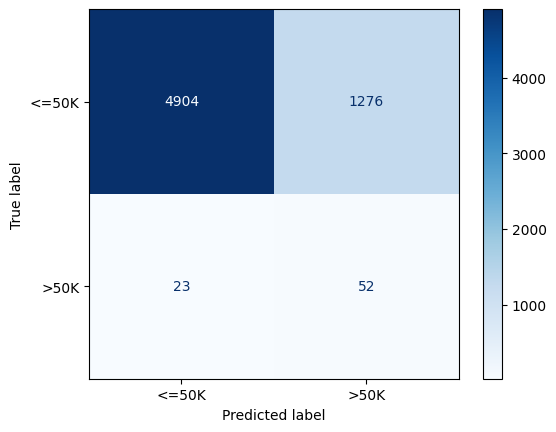

In [39]:
preds3 = gs3.predict(X_test_ss)
evaluation(X_test_ss, y_test, preds3, gs3)

balanced_accuracy: 0.7434304207119742
recall: 0.6933333333333334
precision: 0.0391566265060241
f1 score: 0.07412687099073414


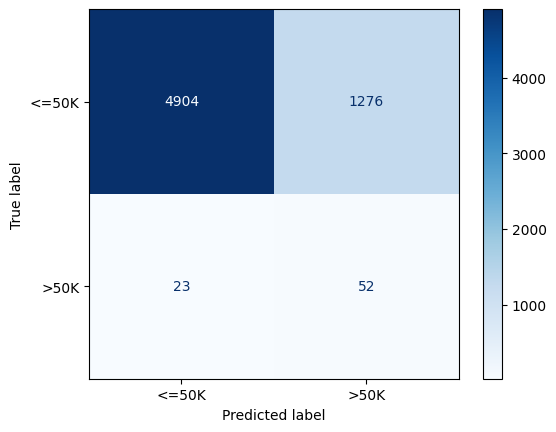

In [40]:
scores.append(evaluation(X_test_ss, y_test, preds3, gs3))

In [41]:
pd.DataFrame(scores, index=['logr', 'RandomOverSampler', 'SMOTE'])

,balanced_accuracy,recall,precision,f1_score
logr,0.533091,0.066667,0.625000,0.120482
RandomOverSampler,0.721650,0.586667,0.047312,0.087562
SMOTE,0.743430,0.693333,0.039157,0.074127


### Effects
By training on different data you can change the decision function.

<img src='../assets/decision-function.png'>

**Source:** the docs

### ADASYN
#### Like SMOTE, but focus on the hard observations. Make more data points like them.

"ADASYN focuses on generating samples next to the original samples which are wrongly classified using a k-Nearest Neighbors classifier while the basic implementation of SMOTE will not make any distinction between easy and hard samples to be classified using the nearest neighbors rule." - the docs

In [42]:
from imblearn.over_sampling import ADASYN

In [43]:
# Make your pipeline with ADASYN 

pipe4 = make_pipeline(ADASYN(random_state=34),
                     LogisticRegression(max_iter=1000))

In [44]:
gs4 = GridSearchCV(
    pipe4, 
    {'logisticregression__C':[.1,1,10],}, 
    scoring='balanced_accuracy',
    n_jobs=-1
)

In [45]:
gs4.fit(X_train_ss, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [0.1, 1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information pr

In [46]:
gs4.score(X_test_ss, y_test)  # balanced accuracy

0.7490614886731392

In [47]:
preds4 = gs4.predict(X_test_ss)

balanced_accuracy: 0.7490614886731392
recall: 0.7466666666666667
precision: 0.035175879396984924
f1 score: 0.06718656268746251


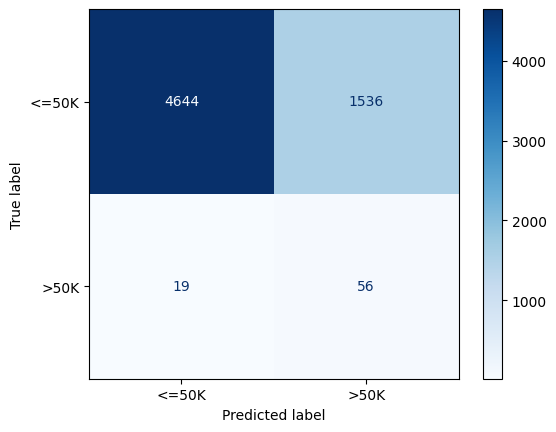

In [48]:
scores.append(evaluation(X_test_ss, y_test, preds4, gs4))

C:\Users\CharleyHanania\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


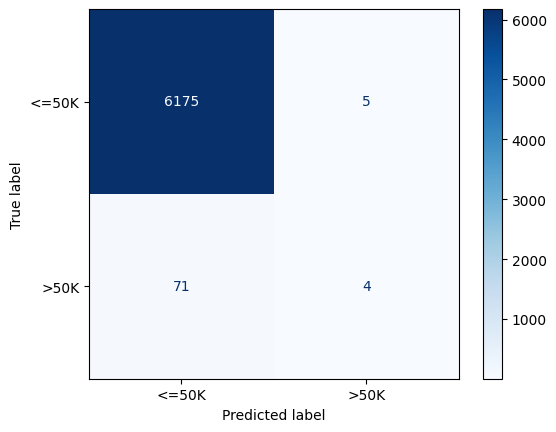

In [49]:
ConfusionMatrixDisplay.from_estimator(gs4, X_test, y_test, cmap="Blues");

### Handling Categorical Features 
 When the features are categorical or a mix of categorical and continuous you need to use special versions of SMOTE: ⚠️

- Use `SMOTENC` for mixed features (categorical and continuous).
- Use `SMOTEN` when you have all categorical features.

Review the examples in [the docs](https://imbalanced-learn.org/stable/over_sampling.html#smote-variants)

### SMOTE variations

There are several other SMOTE algorithms you can use. The ones you've seen above should be enough for most problems. If you want to try others, see the [docs](https://imbalanced-learn.org/stable/over_sampling.html#smote-variants).

---
# Option 3: Overweight minority class importance in algorithms

Some models - such as logistic regression - allow for the errors from the observations of one class to carry more weight. With logistic regression, the minority class observations could affect the betas' weights more, which should help with predictions of the minority class.

You can set the weights manually or, as the Logistic Regression `scikit-learn` docs for the `class_weight` argument explain: 
    
    "The "balanced" mode uses the values of y to automatically adjust weights inversely proportional to class frequencies in the input data..."


In [50]:
logr5 = LogisticRegression(max_iter=1000, class_weight='balanced')

logr5.fit(X_train_ss, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

balanced_accuracy: 0.7407281553398058
recall: 0.68
precision: 0.03990610328638498
f1 score: 0.07538802660753881


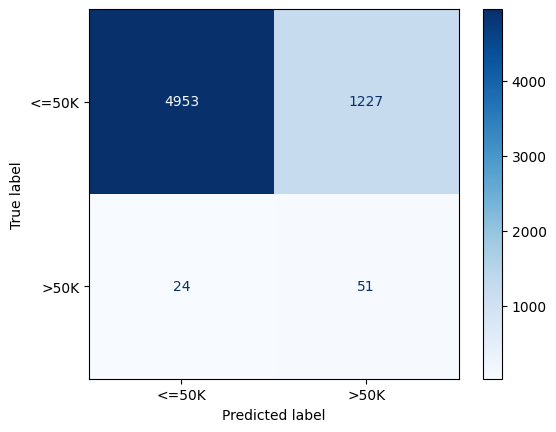

In [51]:
scores.append(evaluation(X_test_ss, y_test, logr5.predict(X_test_ss), logr5))

In [52]:
pd.DataFrame(scores, index=['logr', 'RandomOverSampler', 'SMOTE', 'ADASYN', 'WeightedLogr'])

,balanced_accuracy,recall,precision,f1_score
logr,0.533091,0.066667,0.625000,0.120482
RandomOverSampler,0.721650,0.586667,0.047312,0.087562
SMOTE,0.743430,0.693333,0.039157,0.074127
ADASYN,0.749061,0.746667,0.035176,0.067187
WeightedLogr,0.740728,0.680000,0.039906,0.075388


To learn more about this option, check out [this Machine Learning Mastery article](https://machinelearningmastery.com/cost-sensitive-logistic-regression/).

Note that `imbalanced-learn` also has random forests and boosting ensembles that will balance the data set for training. See more [here](https://imbalanced-learn.org/stable/ensemble.html).

___
# Option 4: Change the class cutoff threshold

We could just adjust our probability threshold cutoff for the minority class to get more minority class predictions.

Our classifier needs to be well calibrated - a 40% probability of class 1 should be correct about 40% of the time.

In [53]:
logr5.predict(X_test_ss)

array(['<=50K', '<=50K', '<=50K', ..., '<=50K', '>50K', '<=50K'],
      dtype=object)

In [54]:
prob = logr5.predict_proba(X_test_ss)[:, 1]

prob[:5]

array([0.26029701, 0.42353539, 0.15447967, 0.09267524, 0.16907493])

In [55]:
(prob >= .5).sum()

1278

In [56]:
(prob >= .4).sum()

1932

--- 
## Summary

Much classification data is imbalanced. You've seen how to deal with it to improve model performance while not overstating your model's likely generalizability.

### Overall approach

- Carefully consider your metrics. 
- You can change the `GridSearchCV` scoring metric.
- Make a baseline null model.
- With a task like image classification with a neural net, you just need enough minority samples. Data augmentation can be helpful. The imbalance doesn't matter that much.
- Getting more data is often helpful. 😉

---
### Techniques to improve model performance on minority class ⭐️⭐️⭐️
1. Oversample the minority class
1. Create syntethic data like the minority class (e.g. use SMOTE)
1. Overweight the minority class importance in your algorithm
1. Change the cutoff if there's a `predict_proba()` function

### Imbalanced learn

The `imbalanced-learn` library can help you by providing a `make_pipeline` that keeps your test set safe.

You can use `imbalanced-learn` to train on a random oversampling of your minority class observations. It can also help you create synthetic data with SMOTE of some variation or ADASYN. 

Don't forget to use `imbalanced-learn`'s pipeline so that the training data has the observations you need and the test set is left untouched.